# Travel Booking Clustering

In [2]:
# Import our modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels as sm
import pylab as pl
from scipy import stats
from sklearn import preprocessing
from sklearn import cluster, tree, decomposition
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LogisticRegression
import pydot

In [3]:
#Download our dataset
file_name="https://raw.githubusercontent.com/rajeevratan84/datascienceforbusiness/master/travel.csv"

travel=pd.read_csv(file_name)

In [4]:
travel.head()

,Unnamed: 0,date_time,site_name,posa_continent,user_location_country,user_location_region,user_location_city,orig_destination_distance,user_id,is_mobile,...,srch_children_cnt,srch_rm_cnt,srch_destination_id,srch_destination_type_id,is_booking,cnt,hotel_continent,hotel_country,hotel_market,hotel_cluster
0,24636210,2014-11-03 16:02:28,24,2,77,871,36643,456.1151,792280,0,...,0,1,8286,1,0,1,0,63,1258,68
1,19837144,2013-03-13 19:25:01,11,3,205,135,38749,232.4737,961995,0,...,0,1,1842,3,0,1,2,198,786,37
2,13066459,2014-10-13 13:20:25,2,3,66,314,48562,4468.2720,495669,0,...,0,1,8746,1,0,1,6,105,29,22
3,4691082,2013-11-05 10:40:34,11,3,205,411,52752,171.6021,106611,0,...,0,1,6210,3,1,1,2,198,1234,42
4,4878884,2014-06-10 13:34:56,2,3,66,174,50644,NaN,596177,0,...,1,1,12812,5,0,1,2,50,368,83


# Dataset Description of fields (added after video was recorded)
![alt text](https://miro.medium.com/max/704/1*qx6uN9Zr1Y2BVtm_yCAv5Q.png)

In [5]:
# Get base information on our dataset
print("Rows     : ", travel.shape[0])
print ("Columns  : " , travel.shape[1])
print ("\nFeatures : \n" ,travel.columns.tolist())
print ("\nMissing values :  ", travel.isnull().sum().values.sum())
print ("\nUnique values :  \n", travel.nunique())

Rows     :  100000
Columns  :  25

Features : 
 ['Unnamed: 0', 'date_time', 'site_name', 'posa_continent', 'user_location_country', 'user_location_region', 'user_location_city', 'orig_destination_distance', 'user_id', 'is_mobile', 'is_package', 'channel', 'srch_ci', 'srch_co', 'srch_adults_cnt', 'srch_children_cnt', 'srch_rm_cnt', 'srch_destination_id', 'srch_destination_type_id', 'is_booking', 'cnt', 'hotel_continent', 'hotel_country', 'hotel_market', 'hotel_cluster']

Missing values :   36329

Unique values :  
 Unnamed: 0                   100000
date_time                     99886
site_name                        41
posa_continent                    5
user_location_country           201
user_location_region            779
user_location_city            10779
orig_destination_distance     62206
user_id                       88863
is_mobile                         2
is_package                        2
channel                          11
srch_ci                        1066
srch_co     

In [6]:
# Get statistics for our Numerical Columns
travel.describe()

,Unnamed: 0,site_name,posa_continent,user_location_country,user_location_region,user_location_city,orig_destination_distance,user_id,is_mobile,is_package,...,srch_children_cnt,srch_rm_cnt,srch_destination_id,srch_destination_type_id,is_booking,cnt,hotel_continent,hotel_country,hotel_market,hotel_cluster
count,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,63915.000000,1.000000e+05,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.882530e+07,9.838570,2.678150,85.995070,308.636990,27676.391240,1960.661721,6.054383e+05,0.133770,0.248140,...,0.336750,1.111750,14426.32738,2.577290,0.079930,1.487980,3.150920,81.093290,598.848330,49.860370
std,1.086183e+07,11.996426,0.749018,59.292002,208.706581,16768.647409,2228.153377,3.516154e+05,0.340407,0.431936,...,0.734449,0.451602,11036.98122,2.149263,0.271186,1.280262,1.620534,56.111519,510.959297,28.885423
min,1.012000e+03,2.000000,0.000000,0.000000,0.000000,0.000000,0.005600,1.400000e+01,0.000000,0.000000,...,0.000000,0.000000,4.00000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,9.448967e+06,2.000000,3.000000,66.000000,174.000000,12949.000000,312.792100,2.987962e+05,0.000000,0.000000,...,0.000000,1.000000,8267.00000,1.000000,0.000000,1.000000,2.000000,50.000000,158.000000,25.000000
50%,1.881212e+07,2.000000,3.000000,66.000000,314.000000,27655.000000,1131.835300,6.028825e+05,0.000000,0.000000,...,0.000000,1.000000,9145.00000,1.000000,0.000000,1.000000,2.000000,50.000000,591.000000,49.000000
75%,2.825307e+07,15.000000,3.000000,70.000000,385.000000,42328.000000,2542.359350,9.157222e+05,0.000000,0.000000,...,0.000000,1.000000,18784.00000,5.000000,0.000000,2.000000,4.000000,106.000000,701.000000,73.000000
max,3.767009e+07,53.000000,4.000000,239.000000,1025.000000,56507.000000,11965.376100,1.198783e+06,1.000000,1.000000,...,9.000000,8.000000,65035.00000,9.000000,1.000000,120.000000,6.000000,212.000000,2117.000000,99.000000


In [7]:
#Find where missing values are located
travel.isnull().sum()

Unnamed: 0                       0
date_time                        0
site_name                        0
posa_continent                   0
user_location_country            0
user_location_region             0
user_location_city               0
orig_destination_distance    36085
user_id                          0
is_mobile                        0
is_package                       0
channel                          0
srch_ci                        122
srch_co                        122
srch_adults_cnt                  0
srch_children_cnt                0
srch_rm_cnt                      0
srch_destination_id              0
srch_destination_type_id         0
is_booking                       0
cnt                              0
hotel_continent                  0
hotel_country                    0
hotel_market                     0
hotel_cluster                    0
dtype: int64

array([[<Axes: title={'center': 'channel'}>,
        <Axes: title={'center': 'is_booking'}>,
        <Axes: title={'center': 'is_mobile'}>],
       [<Axes: title={'center': 'orig_destination_distance'}>,
        <Axes: title={'center': 'srch_rm_cnt'}>,
        <Axes: title={'center': 'srch_adults_cnt'}>],
       [<Axes: title={'center': 'srch_children_cnt'}>, <Axes: >,
        <Axes: >]], dtype=object)

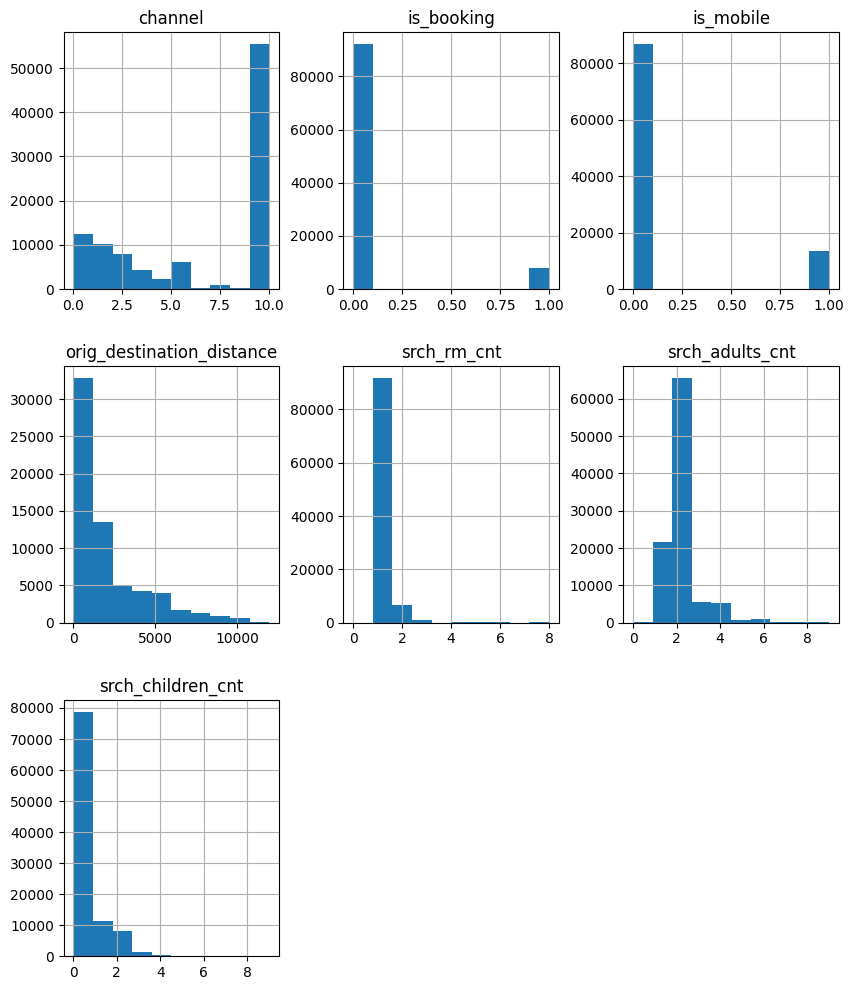

In [8]:
# Plot some of the data
travel[['channel', 'is_booking', 'is_mobile', 'orig_destination_distance', 'srch_rm_cnt', 'srch_adults_cnt', 'srch_children_cnt']].hist(figsize=(10, 12))

In [9]:
# View bookings made per user
booking_count_per_user=travel.groupby("user_id")["is_booking"].agg(['count']).reset_index()
booking_count_per_user.head()

,user_id,count
0,14,1
1,38,1
2,40,1
3,156,2
4,160,1


array([[<Axes: title={'center': 'count'}>]], dtype=object)

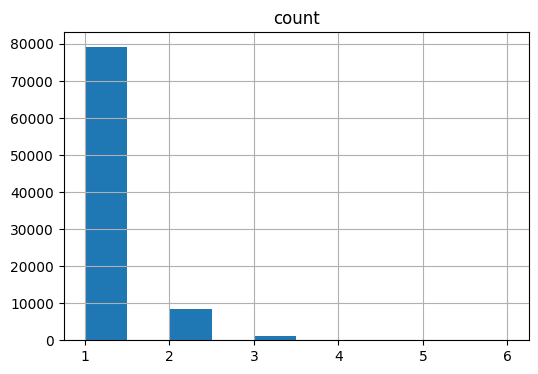

In [10]:
booking_count_per_user[['count']].hist(figsize=(6, 4))

In [11]:
# distribution of number of booking attempts
travel.groupby('user_id')['is_booking'].agg(num_of_booking_attempts='count').reset_index().groupby('num_of_booking_attempts')['user_id'].agg('count')

num_of_booking_attempts
1    79189
2     8423
3     1065
4      161
5       24
6        1
Name: user_id, dtype: int64

In [12]:
# distribution of number of booking attempts
travel.groupby('user_id')['is_booking'].agg(num_of_bookings='sum').reset_index().groupby('num_of_bookings')['user_id'].agg('count')

num_of_bookings
0    80991
1     7753
2      117
3        2
Name: user_id, dtype: int64

## Logic checks

In [13]:
pd.crosstab(travel["srch_adults_cnt"], travel["srch_children_cnt"])

srch_children_cnt,0,1,2,3,4,5,6,7,8,9
srch_adults_cnt,,,,,,,,,,
0,174,2,3,2,0,0,0,0,0,0
1,18749,2137,523,117,11,1,9,1,2,0
2,50736,7093,6529,972,208,14,7,1,0,0
3,3645,1131,469,131,27,5,2,2,0,2
4,3933,690,494,77,83,9,4,0,0,0
5,535,131,41,20,6,4,2,0,0,0
6,669,73,53,28,18,13,7,0,0,0
7,99,20,5,8,6,3,0,0,0,0
8,183,12,13,2,6,1,3,2,2,1


In [14]:
# travel.drop(travel[travel["srch_adults_cnt"]+travel["srch_children_cnt"]==0].index).describe()
travel.drop(travel[travel["srch_adults_cnt"]+travel["srch_children_cnt"]==0].index, inplace=True)
travel.describe()

,Unnamed: 0,site_name,posa_continent,user_location_country,user_location_region,user_location_city,orig_destination_distance,user_id,is_mobile,is_package,...,srch_children_cnt,srch_rm_cnt,srch_destination_id,srch_destination_type_id,is_booking,cnt,hotel_continent,hotel_country,hotel_market,hotel_cluster
count,9.982600e+04,99826.000000,99826.000000,99826.000000,99826.000000,99826.000000,63800.000000,9.982600e+04,99826.000000,99826.000000,...,99826.000000,99826.000000,99826.000000,99826.000000,99826.000000,99826.000000,99826.000000,99826.000000,99826.000000,99826.000000
mean,1.882778e+07,9.837147,2.678360,85.996524,308.575101,27672.791477,1959.922567,6.054342e+05,0.133763,0.246850,...,0.337337,1.111905,14430.614329,2.578467,0.079949,1.487749,3.149801,81.107016,598.891141,49.858364
std,1.086095e+07,11.994507,0.748765,59.299506,208.723143,16769.257097,2228.800100,3.516431e+05,0.340399,0.431181,...,0.734954,0.451914,11039.901710,2.149676,0.271216,1.279821,1.620078,56.114464,510.868287,28.889892
min,1.012000e+03,2.000000,0.000000,0.000000,0.000000,0.000000,0.005600,1.400000e+01,0.000000,0.000000,...,0.000000,1.000000,4.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,9.450324e+06,2.000000,3.000000,66.000000,174.000000,12937.000000,311.901850,2.987725e+05,0.000000,0.000000,...,0.000000,1.000000,8267.000000,1.000000,0.000000,1.000000,2.000000,50.000000,158.000000,25.000000
50%,1.881744e+07,2.000000,3.000000,66.000000,314.000000,27651.500000,1130.000850,6.028735e+05,0.000000,0.000000,...,0.000000,1.000000,9147.000000,1.000000,0.000000,1.000000,2.000000,50.000000,591.000000,49.000000
75%,2.825404e+07,15.000000,3.000000,70.000000,385.000000,42328.000000,2542.103975,9.158898e+05,0.000000,0.000000,...,0.000000,1.000000,18787.000000,5.000000,0.000000,2.000000,4.000000,106.000000,701.000000,73.000000
max,3.767009e+07,53.000000,4.000000,239.000000,1025.000000,56507.000000,11965.376100,1.198783e+06,1.000000,1.000000,...,9.000000,8.000000,65035.000000,9.000000,1.000000,120.000000,6.000000,212.000000,2117.000000,99.000000


In [15]:
# Changing the column type to datetime using pandas
travel["srch_co"]=pd.to_datetime(travel["srch_co"])
travel["srch_ci"]=pd.to_datetime(travel["srch_ci"])
travel["date_time"]=pd.to_datetime(travel["date_time"])

# Change the timestamp of 'date_time' (2014-11-03 16:02:28) to simply "2014-11-03"
travel["date"]=pd.to_datetime(travel["date_time"].apply(lambda x: x.date()))
travel[["date", "srch_ci", "srch_co"]].head()

,date,srch_ci,srch_co
0,2014-11-03,2014-12-15,2014-12-19
1,2013-03-13,2013-03-13,2013-03-14
2,2014-10-13,2015-04-03,2015-04-10
3,2013-11-05,2013-11-07,2013-11-08
4,2014-06-10,2014-08-03,2014-08-08


In [16]:
travel[travel['srch_co'] < travel['srch_ci']][['srch_co', 'srch_ci']]

,srch_co,srch_ci
36906,2015-05-09,2015-08-31
44717,2013-05-27,2013-08-20


In [17]:
# Check-out date need to be later than check-in date;
# Check-in date need to be later than booking date
travel[travel['srch_co'] < travel['srch_ci']][['srch_co', 'srch_ci']]
travel[travel['srch_ci'] < travel['date']][['srch_ci', 'date']]

,srch_ci,date
5809,2014-01-05,2014-01-07
12310,2014-10-13,2014-10-14
19014,2014-02-11,2014-10-09
21780,2014-03-10,2014-09-15
22573,2014-09-12,2014-12-02
25056,2014-08-02,2014-08-23
30802,2013-09-20,2013-09-21
30929,2014-07-08,2014-07-29
35776,2014-12-01,2014-12-02
40107,2014-04-11,2014-10-26


In [18]:
travel.drop(travel[travel['srch_co'] < travel['srch_ci']].index, inplace=True)
#travel.drop(travel[travel['srch_ci'] < travel['date']].index, inplace=True)
travel.describe()

,Unnamed: 0,date_time,site_name,posa_continent,user_location_country,user_location_region,user_location_city,orig_destination_distance,user_id,is_mobile,...,srch_rm_cnt,srch_destination_id,srch_destination_type_id,is_booking,cnt,hotel_continent,hotel_country,hotel_market,hotel_cluster,date
count,9.982400e+04,99824,99824.000000,99824.000000,99824.000000,99824.000000,99824.000000,63800.000000,9.982400e+04,99824.000000,...,99824.000000,99824.000000,99824.000000,99824.000000,99824.000000,99824.000000,99824.000000,99824.000000,99824.000000,99824
mean,1.882766e+07,2014-04-03 08:59:24.951895296,9.836733,2.678384,85.997526,308.570734,27672.781445,1959.922567,6.054362e+05,0.133755,...,1.111907,14430.818811,2.578498,0.079951,1.487758,3.149814,81.106628,598.881421,49.858842,2014-04-02 18:54:01.384837120
min,1.012000e+03,2013-01-07 00:33:47,2.000000,0.000000,0.000000,0.000000,0.000000,0.005600,1.400000e+01,0.000000,...,1.000000,4.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2013-01-07 00:00:00
25%,9.450116e+06,2013-10-24 20:10:31.249999872,2.000000,3.000000,66.000000,174.000000,12937.000000,311.901850,2.987735e+05,0.000000,...,1.000000,8267.000000,1.000000,0.000000,1.000000,2.000000,50.000000,158.000000,25.000000,2013-10-24 00:00:00
50%,1.881685e+07,2014-05-30 11:34:47.500000,2.000000,3.000000,66.000000,314.000000,27651.500000,1130.000850,6.028735e+05,0.000000,...,1.000000,9147.000000,1.000000,0.000000,1.000000,2.000000,50.000000,591.000000,49.000000,2014-05-30 00:00:00
75%,2.825456e+07,2014-09-18 08:13:29.249999872,15.000000,3.000000,70.000000,385.000000,42328.000000,2542.103975,9.158872e+05,0.000000,...,1.000000,18787.000000,5.000000,0.000000,2.000000,4.000000,106.000000,701.000000,73.000000,2014-09-18 00:00:00
max,3.767009e+07,2014-12-31 23:47:14,53.000000,4.000000,239.000000,1025.000000,56507.000000,11965.376100,1.198783e+06,1.000000,...,8.000000,65035.000000,9.000000,1.000000,120.000000,6.000000,212.000000,2117.000000,99.000000,2014-12-31 00:00:00
std,1.086103e+07,NaN,11.994236,0.748751,59.299494,208.711965,16769.185612,2228.800100,3.516396e+05,0.340391,...,0.451919,11039.902947,2.149686,0.271218,1.279832,1.620090,56.114504,510.865621,28.889984,NaN


# Feature Engineering

In [19]:
travel[travel.srch_co.isnull() == True][['date', 'srch_ci', 'srch_co']]
# travel.drop(travel[travel.srch_ci.isnull() == True].index, inplace=True)

,date,srch_ci,srch_co
753,2014-06-22,NaT,NaT
1360,2013-04-13,NaT,NaT
2386,2013-07-12,NaT,NaT
3074,2013-06-01,NaT,NaT
4056,2013-08-07,NaT,NaT
...,...,...,...
95473,2013-07-15,NaT,NaT
95754,2013-12-25,NaT,NaT
96798,2013-06-27,NaT,NaT
98515,2013-06-20,NaT,NaT


In [20]:
#Let's create some new columns that can provide some useful info (not always necesary but help when doing clusters/decision trees)
def duration(row):
    '''Gives the duration of trip by taking the row as an input and finding the time (in days) beween checkin and checkout'''
    delta = (row['srch_co'] - row['srch_ci'])/np.timedelta64(1, 'D')
    if delta < 0:
        return np.nan
    else:
        return delta

def days_in_advance(row):
    '''Gives the days the trip was booked in advance'''
    delta = (row['srch_ci'] - row['date'])/np.timedelta64(1, 'D')
    if delta < 0:
        return np.nan
    else:
        return delta

# Duration is finds the length of stay by substracting the checkout day from the checkin day
travel['duration'] = travel.apply(duration, axis=1)

# Shows how long in advance the booking was made. Done by substracting the checkin date from the booking date
travel['days_in_advance'] = travel.apply(days_in_advance, axis=1)

In [21]:
travel[['date', 'srch_ci', 'srch_co', 'duration', 'days_in_advance']].head()

,date,srch_ci,srch_co,duration,days_in_advance
0,2014-11-03,2014-12-15,2014-12-19,4.0,42.0
1,2013-03-13,2013-03-13,2013-03-14,1.0,0.0
2,2014-10-13,2015-04-03,2015-04-10,7.0,172.0
3,2013-11-05,2013-11-07,2013-11-08,1.0,2.0
4,2014-06-10,2014-08-03,2014-08-08,5.0,54.0


In [22]:
travel[travel.duration.isnull()][['date', 'srch_ci', 'srch_co', 'duration', 'days_in_advance']]

,date,srch_ci,srch_co,duration,days_in_advance
753,2014-06-22,NaT,NaT,NaN,NaN
1360,2013-04-13,NaT,NaT,NaN,NaN
2386,2013-07-12,NaT,NaT,NaN,NaN
3074,2013-06-01,NaT,NaT,NaN,NaN
4056,2013-08-07,NaT,NaT,NaN,NaN
...,...,...,...,...,...
95473,2013-07-15,NaT,NaT,NaN,NaN
95754,2013-12-25,NaT,NaT,NaN,NaN
96798,2013-06-27,NaT,NaT,NaN,NaN
98515,2013-06-20,NaT,NaT,NaN,NaN


### Clustering

In [23]:
# Our selected features
features_to_explore = ['duration', 'days_in_advance', 'orig_destination_distance', 'is_mobile',
            'is_package', 'srch_adults_cnt', 'srch_children_cnt', 'srch_rm_cnt']

# Let's create two new dataframes with our new data called city_data and another where we do a groupby on city_data on user_location_city
city_data = travel.dropna(axis=0)[features_to_explore + ['user_location_city']]
city_groups = city_data.groupby('user_location_city').mean().reset_index().dropna(axis=0)

In [24]:
city_groups.head()

,user_location_city,duration,days_in_advance,orig_destination_distance,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt
0,0,2.000000,78.500000,2315.836250,0.000000,0.250000,1.750000,0.000000,1.0
1,3,4.294118,87.705882,3451.384159,0.058824,0.294118,1.941176,0.470588,1.0
2,7,14.000000,58.000000,5994.864000,0.000000,1.000000,2.000000,0.000000,1.0
3,14,7.000000,35.750000,5342.819100,0.000000,0.000000,2.000000,0.750000,1.0
4,21,5.000000,31.500000,2165.768900,0.000000,0.500000,1.500000,1.000000,1.0


In [25]:
city_groups.shape

(4536, 9)

### Standardize our data

In [26]:
#We see the magnitude variations in our features are large (compare duration to is_mobile for example)

city_groups_std = city_groups.copy()
cols = ['duration', 'days_in_advance', 'orig_destination_distance',	'is_mobile', 'is_package', 'srch_adults_cnt', 'srch_children_cnt', 'srch_rm_cnt']

city_groups_std[cols] = preprocessing.scale(city_groups_std[cols])

city_groups_std.head()

,user_location_city,duration,days_in_advance,orig_destination_distance,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt
0,0,-0.650575,0.481211,0.323998,-0.595282,-0.007378,-0.492741,-0.679413,-0.325182
1,3,0.449293,0.680236,1.029652,-0.336693,0.138135,-0.200616,0.198893,-0.325182
2,7,5.102580,0.038016,2.610226,-0.595282,2.466351,-0.110731,-0.679413,-0.325182
3,14,1.746573,-0.443013,2.205031,-0.595282,-0.831955,-0.110731,0.720387,-0.325182
4,21,0.787714,-0.534895,0.230742,-0.595282,0.817198,-0.874751,1.186987,-0.325182


In [27]:
city_groups_std.describe()

,user_location_city,duration,days_in_advance,orig_destination_distance,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt
count,4536.000000,4.536000e+03,4.536000e+03,4.536000e+03,4.536000e+03,4.536000e+03,4.536000e+03,4.536000e+03,4.536000e+03
mean,28365.145723,8.458842e-17,-1.793588e-16,6.579099e-17,1.002529e-16,-1.133720e-16,-6.297138e-16,2.193033e-17,8.928778e-17
std,16453.684801,1.000110e+00,1.000110e+00,1.000110e+00,1.000110e+00,1.000110e+00,1.000110e+00,1.000110e+00,1.000110e+00
min,0.000000,-1.609434e+00,-1.215903e+00,-1.114550e+00,-5.952816e-01,-8.319547e-01,-3.166813e+00,-6.794135e-01,-3.251817e-01
25%,13983.500000,-6.069905e-01,-6.662490e-01,-6.657211e-01,-5.952816e-01,-8.319547e-01,-3.156272e-01,-6.794135e-01,-3.251817e-01
50%,28573.000000,-1.711454e-01,-1.830415e-01,-2.232878e-01,-5.952816e-01,-2.533046e-01,-1.107308e-01,-2.736742e-01,-3.251817e-01
75%,42560.000000,3.082841e-01,3.406859e-01,2.830690e-01,2.488226e-01,4.049100e-01,9.551545e-02,2.537869e-01,-4.938354e-02
max,56507.000000,1.756775e+01,6.696758e+00,5.986613e+00,3.800721e+00,2.466351e+00,1.058556e+01,1.425179e+01,1.864280e+01


### Implement clustering via K-means

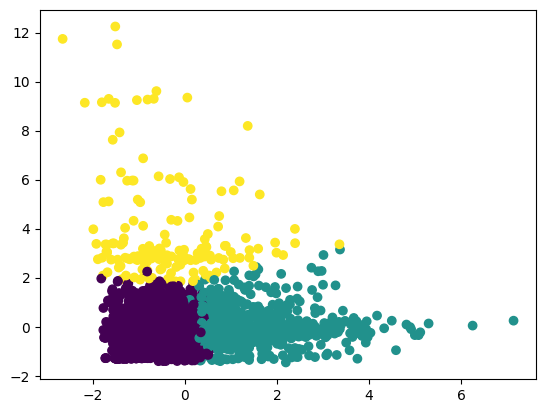

In [140]:
# Let's try arbitrarily 3 clusters 

km = cluster.KMeans(n_clusters=3, max_iter=300, random_state=None)
city_groups_std['cluster'] = km.fit_predict(city_groups_std[features_to_explore])

# Principal Component Analysis for Visualization
pca = decomposition.PCA(n_components=2, whiten=True)
#pca.fit(city_groups[features_to_explore])
city_groups_std['x'] = pca.fit_transform(city_groups_std[features_to_explore])[:, 0]
city_groups_std['y'] = pca.fit_transform(city_groups_std[features_to_explore])[:, 1]
plt.scatter(city_groups_std['x'], city_groups_std['y'], c=city_groups_std['cluster'])
plt.show()

In [141]:
city_groups_std.head()

,user_location_city,duration,days_in_advance,orig_destination_distance,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cluster,x,y
0,0,-0.650575,0.481211,0.323998,-0.595282,-0.007378,-0.492741,-0.679413,-0.325182,0,0.117850,-0.524840
1,3,0.449293,0.680236,1.029652,-0.336693,0.138135,-0.200616,0.198893,-0.325182,1,0.892412,-0.191649
2,7,5.102580,0.038016,2.610226,-0.595282,2.466351,-0.110731,-0.679413,-0.325182,1,3.846187,-0.377569
3,14,1.746573,-0.443013,2.205031,-0.595282,-0.831955,-0.110731,0.720387,-0.325182,1,1.078697,-0.126060
4,21,0.787714,-0.534895,0.230742,-0.595282,0.817198,-0.874751,1.186987,-0.325182,1,0.442991,-0.543385


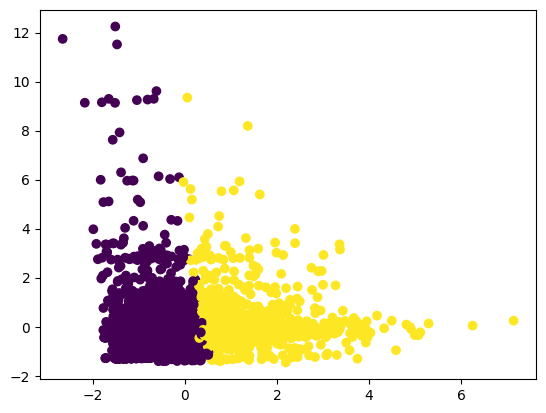

In [30]:
#Let's try it now with 2 clusters

km = cluster.KMeans(n_clusters=2, max_iter=300, random_state=None)
city_groups_std['cluster'] = km.fit_predict(city_groups_std[features_to_explore])

# Principal Component Analysis for Visualization
pca = decomposition.PCA(n_components=2, whiten=True)
city_groups_std['x'] = pca.fit_transform(city_groups_std[features_to_explore])[:, 0]
city_groups_std['y'] = pca.fit_transform(city_groups_std[features_to_explore])[:, 1]
plt.scatter(city_groups_std['x'], city_groups_std['y'], c=city_groups_std['cluster'])
plt.show()

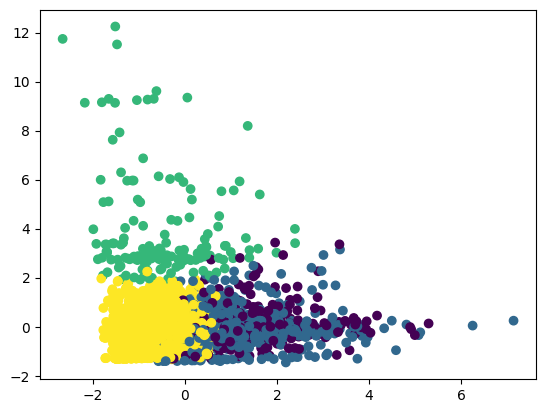

In [31]:
# Now with 4

km = cluster.KMeans(n_clusters=4, max_iter=300, random_state=None)
city_groups_std['cluster'] = km.fit_predict(city_groups_std[features_to_explore])

# Principal Component Analysis for Visualization
pca = decomposition.PCA(n_components=2, whiten=True)

city_groups_std['x'] = pca.fit_transform(city_groups_std[features_to_explore])[:, 0]
city_groups_std['y'] = pca.fit_transform(city_groups_std[features_to_explore])[:, 1]
plt.scatter(city_groups_std['x'], city_groups_std['y'], c=city_groups_std['cluster'])
plt.show()

### Emlbow Method

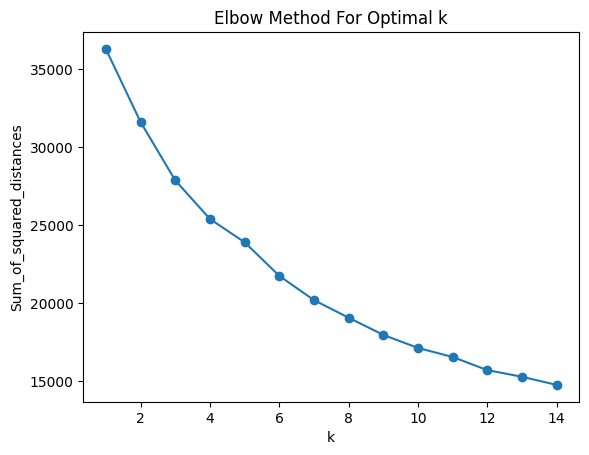

In [128]:
from sklearn.cluster import KMeans

Sum_of_squared_distances = []

# Use k from 1 to 15
K = range(1,15)
for k in K:
    km = KMeans(n_clusters=k, max_iter=300, random_state=26)
    km = km.fit(city_groups_std[features_to_explore])
    # Get sum of square distances by applying km.inertia_ 
    Sum_of_squared_distances.append(km.inertia_)

# Plot Results
plt.plot(K, Sum_of_squared_distances, marker='o')
plt.xlabel('k')
plt.ylabel('Sum_of_squared_distances')
plt.title('Elbow Method For Optimal k')
plt.show()

### Silhouette Coefficient

For n_clusters=2, The Silhouette Coefficient is 0.2424481033622839
For n_clusters=3, The Silhouette Coefficient is 0.25005662592401573
For n_clusters=4, The Silhouette Coefficient is 0.2528162712257526
For n_clusters=5, The Silhouette Coefficient is 0.26080118654696816
For n_clusters=6, The Silhouette Coefficient is 0.2633785123407574
For n_clusters=7, The Silhouette Coefficient is 0.15431610321514894
For n_clusters=8, The Silhouette Coefficient is 0.16222587543678443
For n_clusters=9, The Silhouette Coefficient is 0.17057220714764518
For n_clusters=10, The Silhouette Coefficient is 0.1772680609730423


Text(0, 0.5, 'Silhouette score')

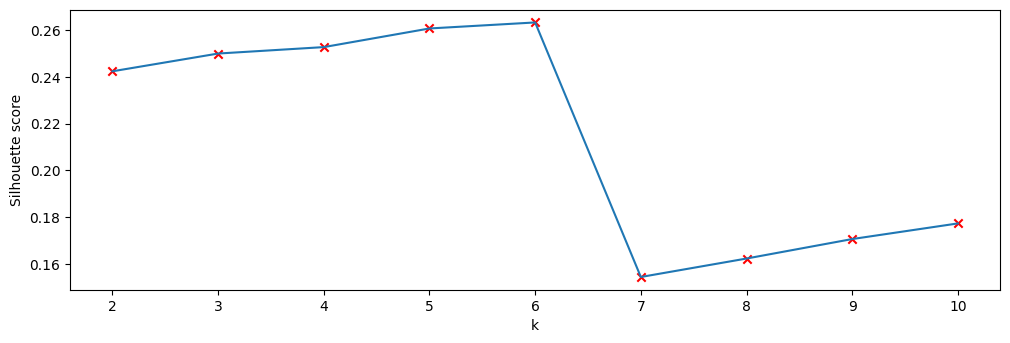

In [122]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

silhouettes = []
ks = list(range(2, 11))
for n_cluster in ks:
    kmeans = KMeans(n_clusters=n_cluster, random_state=41).fit(city_groups_std[features_to_explore])
    label = kmeans.labels_
    sil_coeff = silhouette_score(city_groups_std[features_to_explore], label, metric='euclidean')
    print("For n_clusters={}, The Silhouette Coefficient is {}".format(n_cluster, sil_coeff))
    silhouettes.append(sil_coeff)

plt.figure(figsize=(12, 8))    
plt.subplot(211)
plt.scatter(ks, silhouettes, marker='x', c='r')
plt.plot(ks, silhouettes)
plt.xlabel('k')
plt.ylabel('Silhouette score')

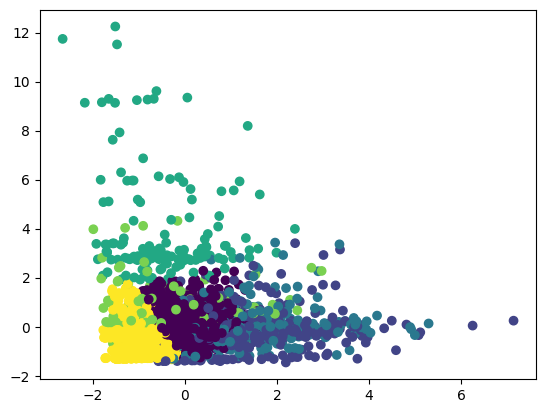

In [34]:
# Now with 6

km = cluster.KMeans(n_clusters=6, max_iter=300, random_state=None)
city_groups_std['cluster'] = km.fit_predict(city_groups_std[features_to_explore])

# Principal Component Analysis for Visualization
pca = decomposition.PCA(n_components=2, whiten=True)

city_groups_std['x'] = pca.fit_transform(city_groups_std[features_to_explore])[:, 0]
city_groups_std['y'] = pca.fit_transform(city_groups_std[features_to_explore])[:, 1]
plt.scatter(city_groups_std['x'], city_groups_std['y'], c=city_groups_std['cluster'])
plt.show()

### Profile and Inspect our 3 clusters

In [142]:
# We will merge the two dataframes based on a common column user_location_city
city_groups.merge(city_groups_std[['user_location_city', 'cluster']]).groupby('cluster').mean() # for every column

,user_location_city,duration,days_in_advance,orig_destination_distance,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt
cluster,,,,,,,,,
0,28011.626828,2.696663,40.544758,1346.211362,0.142215,0.158749,1.982751,0.371092,1.071883
1,28919.287805,5.084050,96.291778,2968.595070,0.117824,0.499625,2.025829,0.319672,1.069853
2,31056.243750,3.063542,56.994427,1581.850799,0.136927,0.188646,4.195000,0.565990,2.451771


<Axes: xlabel='cluster'>

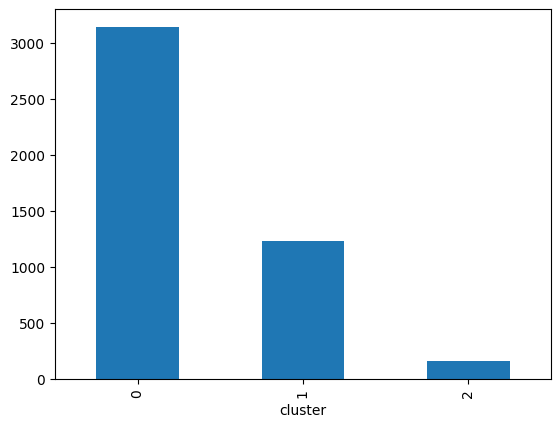

In [143]:
# Plot our Cluster Counts
city_groups_std.groupby('cluster')['user_location_city'].agg('count').plot(kind='bar')

## Grouping by “hotel_market”

### Clustering

In [37]:
# Our selected features
hotel_market_features = ['duration', 'days_in_advance', 'is_mobile', 'is_package', 'channel', 'srch_destination_type_id','srch_adults_cnt',
                       'srch_children_cnt', 'srch_rm_cnt', 'cnt']

# Let's create two new dataframes with our new data called hotel_market_data and another where we do a groupby on hotel_market_data on hotel_market
hotel_market_data = travel.dropna(axis=0)[hotel_market_features + ['hotel_market']]
hotel_market_groups = hotel_market_data.groupby('hotel_market').mean().reset_index().dropna(axis=0)

In [38]:
hotel_market_groups.head()

,hotel_market,duration,days_in_advance,is_mobile,is_package,channel,srch_destination_type_id,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
0,0,3.500000,33.500000,0.000000,0.000000,9.000000,1.000000,1.500000,0.000000,1.000000,2.500000
1,1,1.000000,22.000000,0.000000,1.000000,9.000000,3.000000,2.000000,0.000000,1.000000,1.000000
2,2,3.698113,78.412736,0.101415,0.306604,5.764151,2.188679,2.066038,0.297170,1.120283,1.535377
3,3,2.250000,168.500000,0.000000,0.000000,7.000000,6.000000,1.750000,0.000000,1.000000,1.250000
4,4,3.577381,65.404762,0.053571,0.250000,5.845238,2.202381,1.952381,0.220238,1.125000,1.416667


In [39]:
hotel_market_groups.shape

(1675, 11)

### Standardize our data

In [40]:
hotel_market_groups_std = hotel_market_groups.copy()
cols = ['duration', 'days_in_advance', 'is_mobile', 'is_package', 'channel', 'srch_destination_type_id','srch_adults_cnt',
        'srch_children_cnt', 'srch_rm_cnt', 'cnt']

hotel_market_groups_std[cols] = preprocessing.scale(hotel_market_groups_std[cols])

hotel_market_groups_std.head()

,hotel_market,duration,days_in_advance,is_mobile,is_package,channel,srch_destination_type_id,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
0,0,0.370470,-0.318096,-0.727063,-0.591494,1.483422,-1.252001,-1.008569,-0.786595,-0.434738,1.695715
1,1,-0.972514,-0.633563,-0.727063,4.124209,1.483422,0.155804,0.061424,-0.786595,-0.434738,-0.632231
2,2,0.476895,0.913946,-0.074265,0.854358,-0.140744,-0.415287,0.202744,-0.014780,0.034152,0.198655
3,3,-0.301022,3.385211,-0.727063,-0.591494,0.479565,2.267511,-0.473572,-0.786595,-0.434738,-0.244240
4,4,0.412038,0.557112,-0.382230,0.587431,-0.100044,-0.405642,-0.040480,-0.214588,0.052539,0.014420


In [41]:
hotel_market_groups_std.describe()

,hotel_market,duration,days_in_advance,is_mobile,is_package,channel,srch_destination_type_id,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
count,1675.000000,1.675000e+03,1.675000e+03,1.675000e+03,1.675000e+03,1.675000e+03,1.675000e+03,1.675000e+03,1.675000e+03,1.675000e+03,1.675000e+03
mean,975.739701,-1.739239e-16,-4.242046e-17,8.484092e-17,-5.090455e-17,2.990643e-16,2.205864e-16,3.096694e-16,1.484716e-17,-3.330006e-16,4.878353e-17
std,594.038178,1.000299e+00,1.000299e+00,1.000299e+00,1.000299e+00,1.000299e+00,1.000299e+00,1.000299e+00,1.000299e+00,1.000299e+00,1.000299e+00
min,0.000000,-1.151578e+00,-1.237065e+00,-7.270632e-01,-5.914944e-01,-3.033938e+00,-1.252001e+00,-2.078562e+00,-7.865946e-01,-4.347384e-01,-6.322315e-01
25%,476.500000,-6.143848e-01,-7.185399e-01,-7.270632e-01,-5.914944e-01,-5.242932e-01,-7.723170e-01,-4.735724e-01,-7.865946e-01,-4.347384e-01,-6.322315e-01
50%,931.000000,-3.278816e-01,-2.678041e-01,-2.319175e-01,-5.914944e-01,-1.841212e-02,-1.257570e-01,6.142433e-02,-2.094351e-01,-4.347384e-01,-1.356029e-01
75%,1464.500000,3.395690e-01,5.400770e-01,3.457524e-01,1.944561e-01,5.737142e-01,5.077550e-01,2.992006e-01,3.939589e-01,9.683744e-02,1.608444e-01
max,2117.000000,1.030855e+01,8.213227e+00,5.709831e+00,4.124209e+00,1.483422e+00,2.502145e+00,1.290135e+01,8.303667e+00,1.905638e+01,2.109527e+01


### Emlbow Method (K-means)

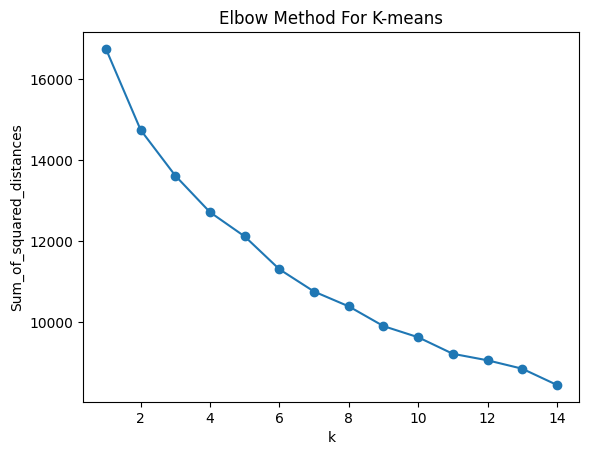

In [92]:
Sum_of_squared_distances = []

# Use k from 1 to 15
K = range(1,15)
for k in K:
    km = KMeans(n_clusters=k, max_iter=300, random_state=22)
    km = km.fit(hotel_market_groups_std[hotel_market_features])
    # Get sum of square distances by applying km.inertia_ 
    Sum_of_squared_distances.append(km.inertia_)

# Plot Results
plt.plot(K, Sum_of_squared_distances, marker='o')
plt.xlabel('k')
plt.ylabel('Sum_of_squared_distances')
plt.title('Elbow Method For K-means')
plt.show()

### Silhouette Coefficient (K-means)

For n_clusters=2, The Silhouette Coefficient is 0.20696976973314443
For n_clusters=3, The Silhouette Coefficient is 0.216885847191651
For n_clusters=4, The Silhouette Coefficient is 0.13301029965139347
For n_clusters=5, The Silhouette Coefficient is 0.08666216169978008
For n_clusters=6, The Silhouette Coefficient is 0.10147970441393
For n_clusters=7, The Silhouette Coefficient is 0.10109517627040145
For n_clusters=8, The Silhouette Coefficient is 0.1216698289241249
For n_clusters=9, The Silhouette Coefficient is 0.1070315164592056
For n_clusters=10, The Silhouette Coefficient is 0.11021044983960246


Text(0, 0.5, 'Silhouette score')

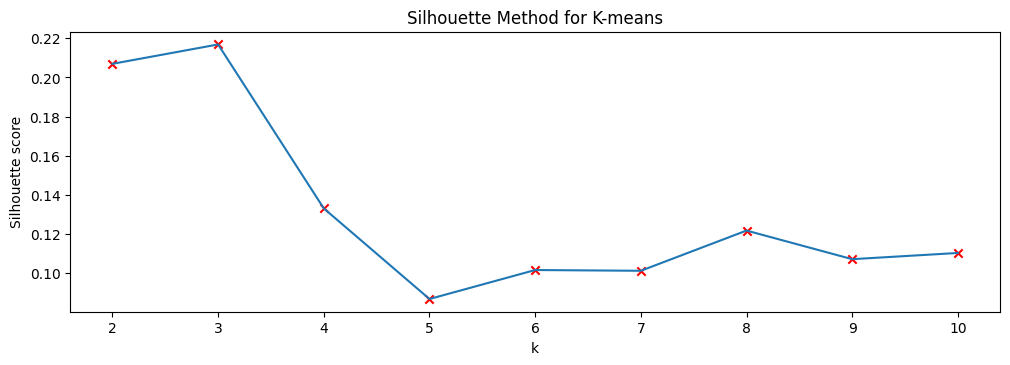

In [43]:
silhouettes = []
ks = list(range(2, 11))
for n_cluster in ks:
    kmeans = KMeans(n_clusters=n_cluster, random_state=22).fit(hotel_market_groups_std[hotel_market_features])
    label = kmeans.labels_
    sil_coeff = silhouette_score(hotel_market_groups_std[hotel_market_features], label, metric='euclidean')
    print("For n_clusters={}, The Silhouette Coefficient is {}".format(n_cluster, sil_coeff))
    silhouettes.append(sil_coeff)

plt.figure(figsize=(12, 8))    
plt.subplot(211)
plt.scatter(ks, silhouettes, marker='x', c='r')
plt.plot(ks, silhouettes)
plt.title("Silhouette Method for K-means")
plt.xlabel('k')
plt.ylabel('Silhouette score')

### Emlbow Method (GMM)

Text(0.5, 1.0, 'Elbow method for GMM')

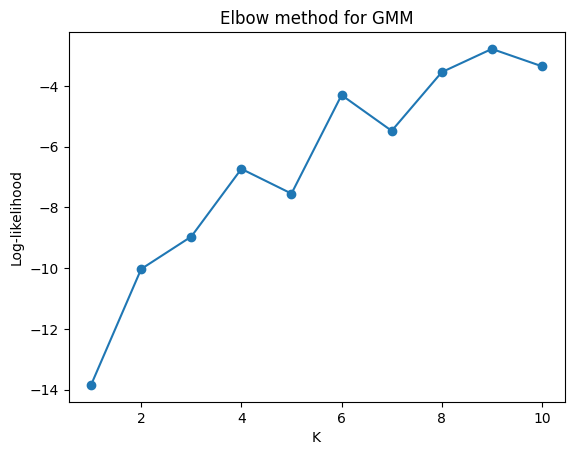

In [44]:
log_likelihood = []
ks = range(1, 11)

for k in ks:
    gmm = GaussianMixture(n_components=k, random_state=20)
    gmm.fit(hotel_market_groups_std[hotel_market_features])
    log_likelihood.append(gmm.score(hotel_market_groups_std[hotel_market_features]))

plt.plot(ks, log_likelihood, marker='o')
plt.xlabel("K")
plt.ylabel("Log-likelihood")
plt.title("Elbow method for GMM")

### Silhouette Coefficient (GMM)

For n_clusters=2, Silhouette Score = 0.0665
For n_clusters=3, Silhouette Score = 0.1286
For n_clusters=4, Silhouette Score = -0.0634
For n_clusters=5, Silhouette Score = -0.0640
For n_clusters=6, Silhouette Score = -0.0604
For n_clusters=7, Silhouette Score = -0.0842
For n_clusters=8, Silhouette Score = -0.1192
For n_clusters=9, Silhouette Score = -0.1037
For n_clusters=10, Silhouette Score = -0.1326


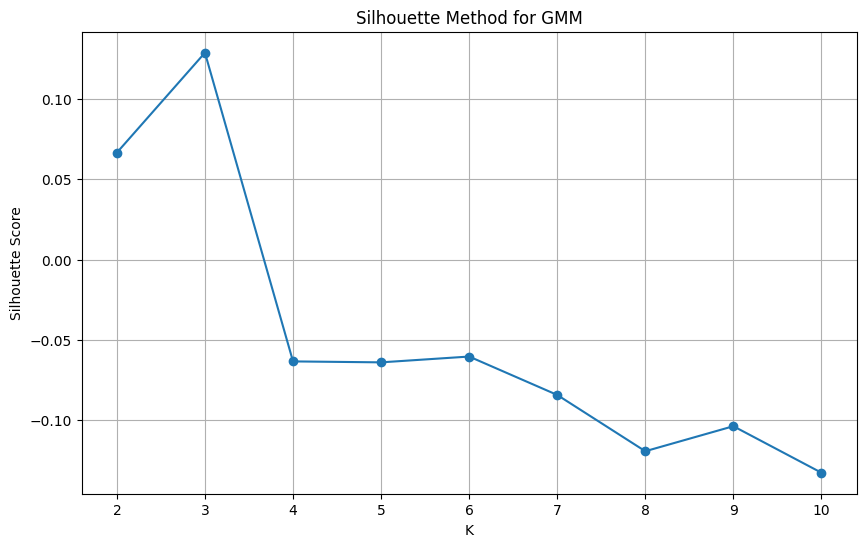

In [45]:
silhouettes = []
ks = range(2, 11)

for k in ks:
    gmm = GaussianMixture(n_components=k, random_state=21)
    gmm.fit(hotel_market_groups_std[hotel_market_features])
    labels = gmm.predict(hotel_market_groups_std[hotel_market_features])

    sil = silhouette_score(hotel_market_groups_std[hotel_market_features], labels, metric='euclidean')
    print(f"For n_clusters={k}, Silhouette Score = {sil:.4f}")
    
    silhouettes.append(sil)

plt.figure(figsize=(10, 6))
plt.plot(ks, silhouettes, marker='o')
plt.title("Silhouette Method for GMM")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

### BIC (GMM)

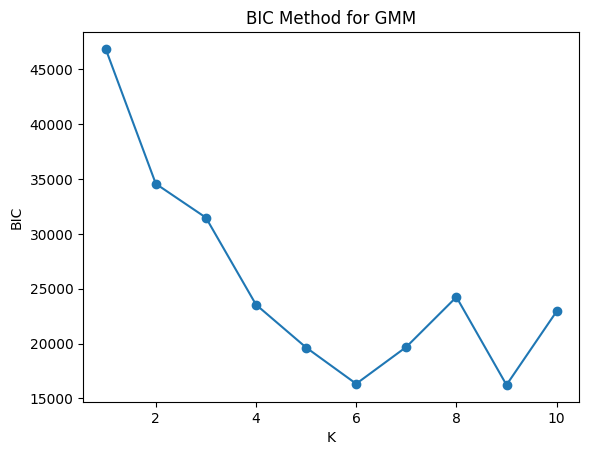

In [46]:
bics = []
ks = range(1, 11)

for k in ks:
    gmm = GaussianMixture(n_components=k, random_state=42)
    gmm.fit(hotel_market_groups_std[hotel_market_features])
    bics.append(gmm.bic(hotel_market_groups_std[hotel_market_features]))

plt.plot(ks, bics, marker='o')
plt.xlabel("K")
plt.ylabel("BIC")
plt.title("BIC Method for GMM")
plt.show()

### Implement clustering via K-means

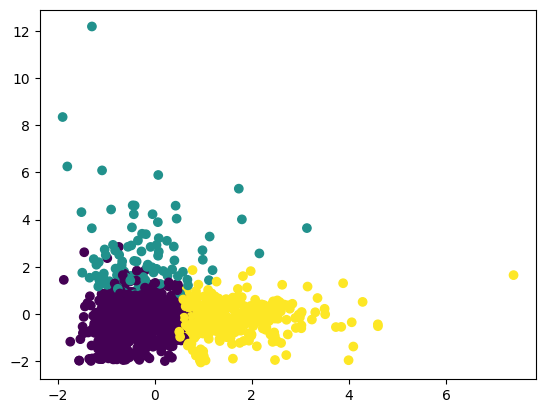

In [47]:
km = cluster.KMeans(n_clusters=3, max_iter=300, random_state=22)
hotel_market_groups_std['cluster_kmeans'] = km.fit_predict(hotel_market_groups_std[hotel_market_features])

# Principal Component Analysis for Visualization
pca = decomposition.PCA(n_components=2, whiten=True)
hotel_market_groups_std['x'] = pca.fit_transform(hotel_market_groups_std[hotel_market_features])[:, 0]
hotel_market_groups_std['y'] = pca.fit_transform(hotel_market_groups_std[hotel_market_features])[:, 1]
plt.scatter(hotel_market_groups_std['x'], hotel_market_groups_std['y'], c=hotel_market_groups_std['cluster_kmeans'])
plt.show()

### Profile and Inspect our 3 clusters (K-means)

In [48]:
# We will merge the two dataframes based on a common column hotel_market
hotel_market_groups.merge(hotel_market_groups_std[['hotel_market', 'cluster_kmeans']]).groupby('cluster_kmeans').mean() # for every column

,hotel_market,duration,days_in_advance,is_mobile,is_package,channel,srch_destination_type_id,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
cluster_kmeans,,,,,,,,,,,
0,962.749169,2.168650,34.206878,0.114713,0.048518,6.058608,2.847066,1.893261,0.304656,1.069971,1.363294
1,1142.942857,2.486999,43.880295,0.113408,0.075576,6.383199,2.968459,2.907181,0.464647,1.759363,1.280949
2,970.505464,5.014109,81.265075,0.107031,0.392747,5.901182,2.499164,1.959513,0.250540,1.062355,1.588654


<Axes: xlabel='cluster_kmeans'>

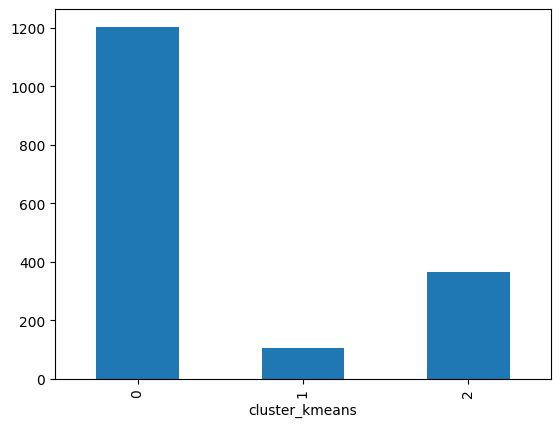

In [49]:
# Plot our Cluster Counts
hotel_market_groups_std.groupby('cluster_kmeans')['hotel_market'].agg('count').plot(kind='bar')

### Implement clustering via GMM

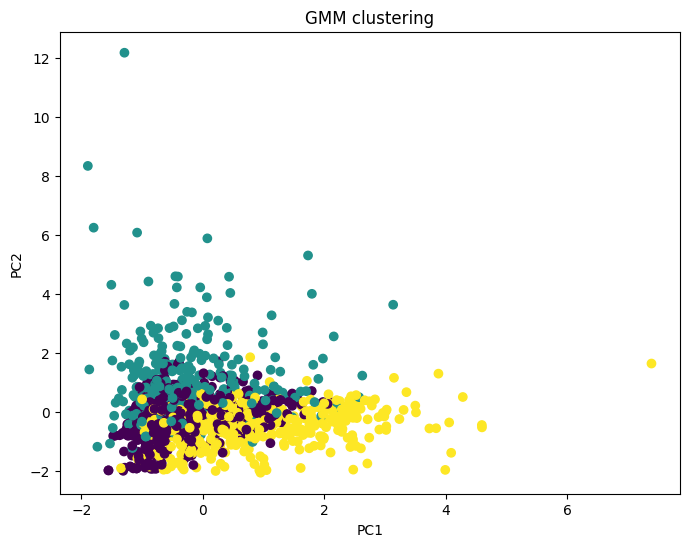

In [50]:
# GMM clustering
gmm = GaussianMixture(n_components=3, covariance_type='full',random_state=22)

hotel_market_groups_std['cluster_gmm'] = gmm.fit_predict(hotel_market_groups_std[hotel_market_features])

# Principal Component Analysis for Visualization
pca = decomposition.PCA(n_components=2, whiten=True)

hotel_market_groups_std['x'] = pca.fit_transform(hotel_market_groups_std[hotel_market_features])[:, 0]

hotel_market_groups_std['y'] = pca.fit_transform(hotel_market_groups_std[hotel_market_features])[:, 1]

# Plot clusters
plt.figure(figsize=(8, 6))
plt.scatter(hotel_market_groups_std['x'], hotel_market_groups_std['y'], c=hotel_market_groups_std['cluster_gmm'])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("GMM clustering")
plt.show()

### Profile and Inspect our 3 clusters (GMM)

In [51]:
# Merge aggregated data with GMM cluster labels
hotel_market_groups.merge(hotel_market_groups_std[['hotel_market', 'cluster_gmm']]).groupby('cluster_gmm').mean()

,hotel_market,duration,days_in_advance,is_mobile,is_package,channel,srch_destination_type_id,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
cluster_gmm,,,,,,,,,,,
0,857.046790,2.330477,36.480342,0.105024,0.075983,6.278593,2.687327,1.928619,0.288357,1.076814,1.327063
1,1129.095395,2.624383,42.380648,0.202056,0.091090,6.004861,2.930254,2.300628,0.500041,1.369251,1.307372
2,1113.922566,3.911134,64.438892,0.069144,0.249064,5.595416,2.862389,1.836571,0.199733,1.008751,1.637923


<Axes: xlabel='cluster_gmm'>

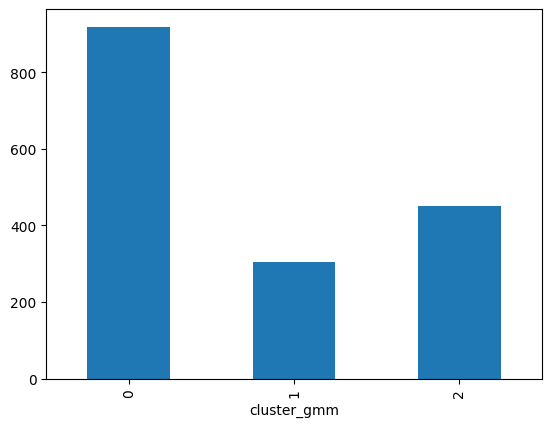

In [52]:
# Plot cluster counts for GMM
hotel_market_groups_std.groupby('cluster_gmm')['hotel_market'].agg('count').plot(kind='bar')

## Grouping by “srch_destination_id”

### Clustering

In [53]:
# Our selected features
srch_destination_features = ['duration', 'days_in_advance', 'orig_destination_distance', 'posa_continent', 'channel', 'srch_destination_type_id',
                       'is_mobile', 'is_package', 'srch_adults_cnt', 'srch_children_cnt', 'srch_rm_cnt', 'cnt']

# Let's create two new dataframes with our new data called srch_destination_data and another where we do a groupby on srch_destination_data on srch_destination_id
srch_destination_data = travel.dropna(axis=0)[srch_destination_features + ['srch_destination_id']]
srch_destination_groups = srch_destination_data.groupby('srch_destination_id').mean().reset_index().dropna(axis=0)

In [54]:
srch_destination_groups.head()

,srch_destination_id,duration,days_in_advance,orig_destination_distance,posa_continent,channel,srch_destination_type_id,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
0,4,4.000000,7.000000,1008.464600,1.0,9.000000,1.0,0.000000,1.0,3.000000,0.000000,3.000000,1.000000
1,8,1.444444,26.444444,402.140656,3.0,5.444444,1.0,0.111111,0.0,1.888889,0.111111,1.111111,1.777778
2,11,1.000000,14.000000,1166.452300,3.0,9.000000,3.0,0.000000,0.0,3.000000,0.000000,1.000000,1.000000
3,14,3.000000,7.000000,7875.489400,3.0,3.000000,3.0,0.000000,0.0,1.000000,0.000000,1.000000,1.000000
4,16,2.500000,58.000000,513.440050,3.0,5.000000,1.0,0.000000,0.5,1.000000,0.000000,1.000000,1.500000


In [55]:
srch_destination_groups.shape

(6768, 13)

### Standardize our data

In [56]:
srch_destination_groups_std = srch_destination_groups.copy()
cols = ['duration', 'days_in_advance', 'orig_destination_distance', 'posa_continent', 'channel', 'srch_destination_type_id',
        'is_mobile', 'is_package', 'srch_adults_cnt', 'srch_children_cnt', 'srch_rm_cnt', 'cnt']

srch_destination_groups_std[cols] = preprocessing.scale(srch_destination_groups_std[cols])

srch_destination_groups_std.head()

,srch_destination_id,duration,days_in_advance,orig_destination_distance,posa_continent,channel,srch_destination_type_id,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
0,4,0.575291,-0.752509,-0.421288,-3.321748,1.035915,-1.567627,-0.478561,3.918784,1.434528,-0.564815,4.810214,-0.520314
1,8,-0.551615,-0.353300,-0.675484,0.256333,-0.143196,-1.567627,-0.052149,-0.390513,-0.123972,-0.365780,-0.011969,0.483061
2,11,-0.747599,-0.608794,-0.355053,0.256333,1.035915,-0.512198,-0.478561,-0.390513,1.434528,-0.564815,-0.295627,-0.520314
3,14,0.134328,-0.752509,2.457653,0.256333,-0.953834,-0.512198,-0.478561,-0.390513,-1.370773,-0.564815,-0.295627,-0.520314
4,16,-0.086154,0.294559,-0.628823,0.256333,-0.290584,-1.567627,-0.478561,1.764136,-1.370773,-0.564815,-0.295627,0.124713


In [57]:
srch_destination_groups_std.describe()

,srch_destination_id,duration,days_in_advance,orig_destination_distance,posa_continent,channel,srch_destination_type_id,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
count,6768.000000,6.768000e+03,6.768000e+03,6.768000e+03,6.768000e+03,6.768000e+03,6.768000e+03,6.768000e+03,6.768000e+03,6.768000e+03,6.768000e+03,6.768000e+03,6.768000e+03
mean,22916.995124,-2.099713e-17,-8.398850e-18,-7.558965e-17,-7.390988e-16,1.679770e-16,8.398850e-17,9.711171e-17,6.719080e-17,6.719080e-17,7.244008e-17,3.212560e-16,2.587896e-16
std,15232.761046,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00
min,4.000000,-1.188562e+00,-8.962247e-01,-8.440472e-01,-5.110788e+00,-1.948708e+00,-1.567627e+00,-4.785606e-01,-3.905132e-01,-1.370773e+00,-5.648154e-01,-2.956267e-01,-5.203140e-01
25%,11996.750000,-7.475990e-01,-6.909172e-01,-7.193637e-01,2.563326e-01,-6.222090e-01,-5.121979e-01,-4.785606e-01,-3.905132e-01,-4.356726e-01,-5.648154e-01,-2.956267e-01,-5.203140e-01
50%,22395.500000,-3.066357e-01,-3.008330e-01,-4.848639e-01,2.563326e-01,1.020369e-01,1.551642e-02,-4.785606e-01,-3.905132e-01,3.187756e-02,-5.648154e-01,-2.956267e-01,-5.203140e-01
75%,28722.250000,1.915782e-01,3.484519e-01,5.468191e-01,2.563326e-01,1.035915e+00,1.070945e+00,3.313333e-02,-3.905132e-01,3.187756e-02,2.605882e-01,-2.956267e-01,1.247127e-01
max,65035.000000,1.600900e+01,8.178366e+00,4.069856e+00,2.045373e+00,1.035915e+00,2.126374e+00,3.359144e+00,3.918784e+00,9.850430e+00,1.018311e+01,1.757482e+01,1.754043e+01


### Emlbow Method (K-means)

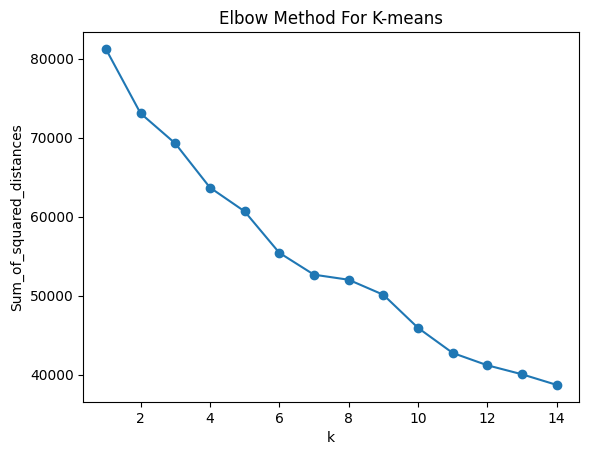

In [83]:
Sum_of_squared_distances = []

# Use k from 1 to 15
K = range(1,15)
for k in K:
    km = KMeans(n_clusters=k, max_iter=300, random_state=20)
    km = km.fit(srch_destination_groups_std[srch_destination_features])
    # Get sum of square distances by applying km.inertia_ 
    Sum_of_squared_distances.append(km.inertia_)

# Plot Results
plt.plot(K, Sum_of_squared_distances, marker='o')
plt.xlabel('k')
plt.ylabel('Sum_of_squared_distances')
plt.title('Elbow Method For K-means')
plt.show()

### Silhouette Coefficient (K-means)

For n_clusters=2, The Silhouette Coefficient is 0.09240822409988121
For n_clusters=3, The Silhouette Coefficient is 0.16370836116532644
For n_clusters=4, The Silhouette Coefficient is 0.1558719989384878
For n_clusters=5, The Silhouette Coefficient is 0.15805197813425756
For n_clusters=6, The Silhouette Coefficient is 0.11346368485477532
For n_clusters=7, The Silhouette Coefficient is 0.11335986776135351
For n_clusters=8, The Silhouette Coefficient is 0.1099472188491024
For n_clusters=9, The Silhouette Coefficient is 0.11994106458937455
For n_clusters=10, The Silhouette Coefficient is 0.12379584686872716


Text(0, 0.5, 'Silhouette score')

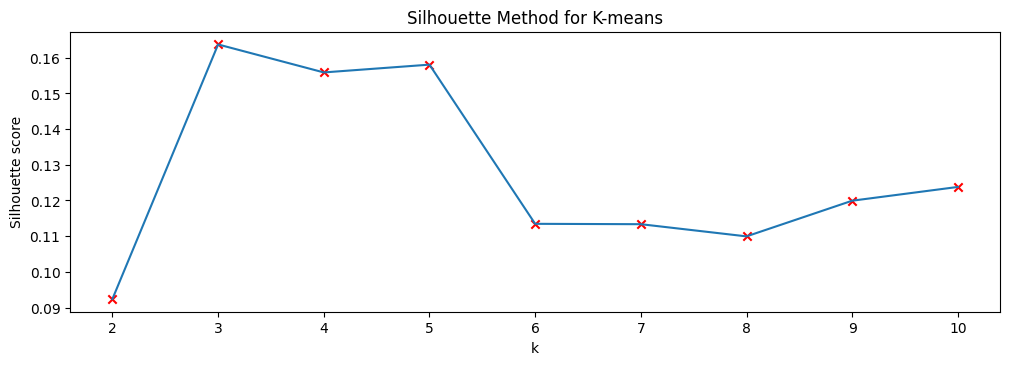

In [59]:
silhouettes = []
ks = list(range(2, 11))
for n_cluster in ks:
    kmeans = KMeans(n_clusters=n_cluster, random_state=35).fit(srch_destination_groups_std[srch_destination_features])
    label = kmeans.labels_
    sil_coeff = silhouette_score(srch_destination_groups_std[srch_destination_features], label, metric='euclidean')
    print("For n_clusters={}, The Silhouette Coefficient is {}".format(n_cluster, sil_coeff))
    silhouettes.append(sil_coeff)

plt.figure(figsize=(12, 8))    
plt.subplot(211)
plt.scatter(ks, silhouettes, marker='x', c='r')
plt.plot(ks, silhouettes)
plt.title("Silhouette Method for K-means")
plt.xlabel('k')
plt.ylabel('Silhouette score')

### Emlbow Method (GMM)

Text(0.5, 1.0, 'Elbow method for GMM')

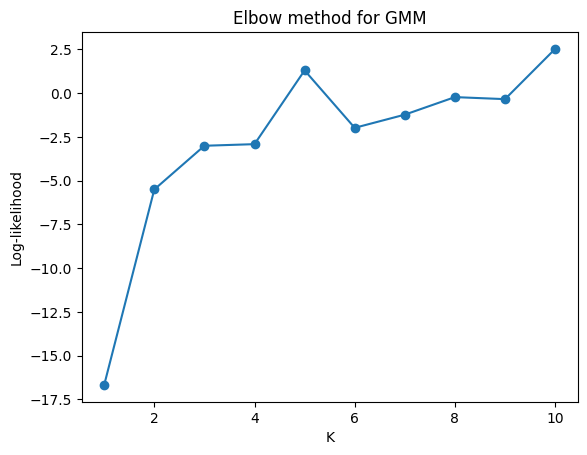

In [60]:
log_likelihood = []
ks = range(1, 11)

for k in ks:
    gmm = GaussianMixture(n_components=k, random_state=25)
    gmm.fit(srch_destination_groups_std[srch_destination_features])
    log_likelihood.append(gmm.score(srch_destination_groups_std[srch_destination_features]))

plt.plot(ks, log_likelihood, marker='o')
plt.xlabel("K")
plt.ylabel("Log-likelihood")
plt.title("Elbow method for GMM")

### Silhouette Coefficient (GMM)

For n_clusters=2, Silhouette Score = 0.0442
For n_clusters=3, Silhouette Score = 0.0710
For n_clusters=4, Silhouette Score = -0.0859
For n_clusters=5, Silhouette Score = -0.0343
For n_clusters=6, Silhouette Score = -0.0243
For n_clusters=7, Silhouette Score = -0.0299
For n_clusters=8, Silhouette Score = -0.0558
For n_clusters=9, Silhouette Score = -0.1191
For n_clusters=10, Silhouette Score = -0.1362


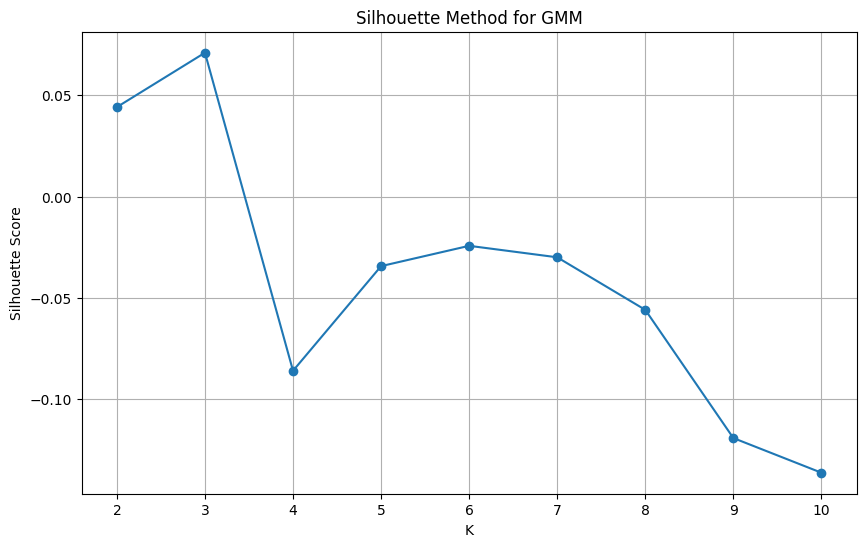

In [61]:
silhouettes = []
ks = range(2, 11)

for k in ks:
    gmm = GaussianMixture(n_components=k, random_state=23)
    gmm.fit(srch_destination_groups_std[srch_destination_features])
    labels = gmm.predict(srch_destination_groups_std[srch_destination_features])

    sil = silhouette_score(srch_destination_groups_std[srch_destination_features], labels, metric='euclidean')
    print(f"For n_clusters={k}, Silhouette Score = {sil:.4f}")
    
    silhouettes.append(sil)

plt.figure(figsize=(10, 6))
plt.plot(ks, silhouettes, marker='o')
plt.title("Silhouette Method for GMM")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

### BIC (GMM)

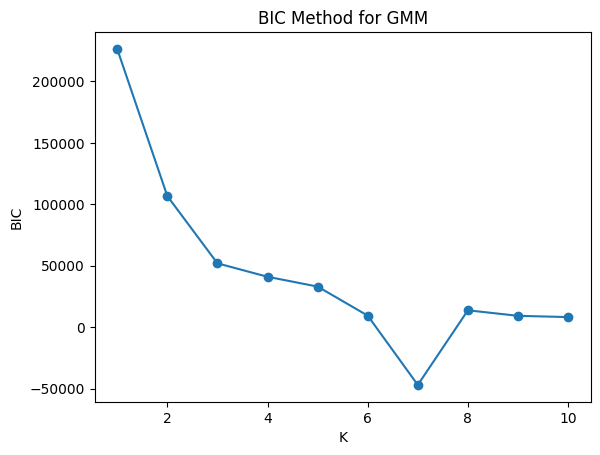

In [98]:
bics = []
ks = range(1, 11)

for k in ks:
    gmm = GaussianMixture(n_components=k, random_state=26)
    gmm.fit(srch_destination_groups_std[srch_destination_features])
    bics.append(gmm.bic(srch_destination_groups_std[srch_destination_features]))

plt.plot(ks, bics, marker='o')
plt.xlabel("K")
plt.ylabel("BIC")
plt.title("BIC Method for GMM")
plt.show()

### Implement clustering via K-means

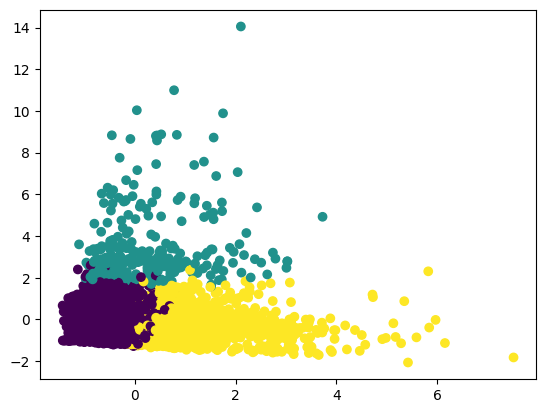

In [63]:
km = cluster.KMeans(n_clusters=3, max_iter=300, random_state=32)
srch_destination_groups_std['cluster_kmeans'] = km.fit_predict(srch_destination_groups_std[srch_destination_features])

# Principal Component Analysis for Visualization
pca = decomposition.PCA(n_components=2, whiten=True)
srch_destination_groups_std['x'] = pca.fit_transform(srch_destination_groups_std[srch_destination_features])[:, 0]
srch_destination_groups_std['y'] = pca.fit_transform(srch_destination_groups_std[srch_destination_features])[:, 1]
plt.scatter(srch_destination_groups_std['x'], srch_destination_groups_std['y'], c=srch_destination_groups_std['cluster_kmeans'])
plt.show()

### Profile and Inspect our 3 clusters (K-means)

In [64]:
# We will merge the two dataframes based on a common column srch_destination_id
srch_destination_groups.merge(srch_destination_groups_std[['srch_destination_id', 'cluster_kmeans']]).groupby('cluster_kmeans').mean() # for every column

,srch_destination_id,duration,days_in_advance,orig_destination_distance,posa_continent,channel,srch_destination_type_id,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
cluster_kmeans,,,,,,,,,,,,,
0,22715.351278,2.013125,25.195995,839.200515,2.871150,5.953731,3.988690,0.135574,0.028765,1.865753,0.342632,1.054571,1.370444
1,26612.118243,2.455483,45.113733,1812.697623,2.750450,5.661192,4.047297,0.108234,0.071722,3.982711,0.426768,2.435875,1.403744
2,22818.365675,4.200616,83.226231,4573.214065,2.840954,5.740257,3.920527,0.103635,0.226681,1.928234,0.240319,1.057267,1.474148


<Axes: xlabel='cluster_kmeans'>

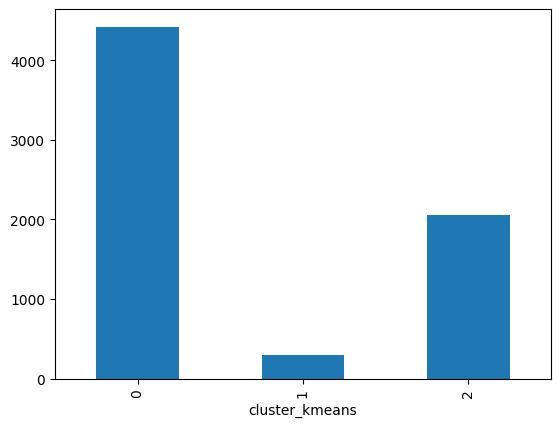

In [65]:
# Plot our Cluster Counts
srch_destination_groups_std.groupby('cluster_kmeans')['srch_destination_id'].agg('count').plot(kind='bar')

### Implement clustering via GMM

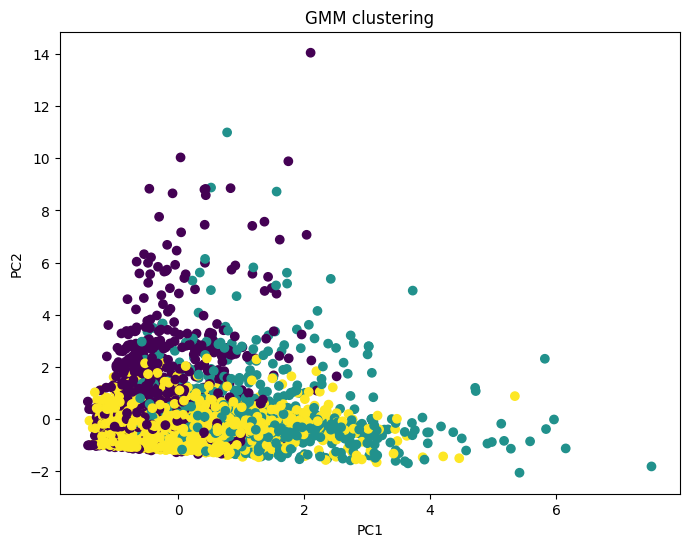

In [66]:
# GMM clustering
gmm = GaussianMixture(n_components=3, covariance_type='full',random_state=22)

srch_destination_groups_std['cluster_gmm'] = gmm.fit_predict(srch_destination_groups_std[srch_destination_features])

# Principal Component Analysis for Visualization
pca = decomposition.PCA(n_components=2, whiten=True)

srch_destination_groups_std['x'] = pca.fit_transform(srch_destination_groups_std[srch_destination_features])[:, 0]

srch_destination_groups_std['y'] = pca.fit_transform(srch_destination_groups_std[srch_destination_features])[:, 1]

# Plot clusters
plt.figure(figsize=(8, 6))
plt.scatter(srch_destination_groups_std['x'], srch_destination_groups_std['y'], c=srch_destination_groups_std['cluster_gmm'])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("GMM clustering")
plt.show()

### Profile and Inspect our 3 clusters (GMM)

In [67]:
# Merge aggregated data with GMM cluster labels
srch_destination_groups.merge(srch_destination_groups_std[['srch_destination_id', 'cluster_gmm']]).groupby('cluster_gmm').mean()

,srch_destination_id,duration,days_in_advance,orig_destination_distance,posa_continent,channel,srch_destination_type_id,is_mobile,is_package,srch_adults_cnt,srch_children_cnt,srch_rm_cnt,cnt
cluster_gmm,,,,,,,,,,,,,
0,22708.725195,2.120699,32.025098,1270.026188,3.000000,5.934567,3.919423,0.354474,0.012028,2.246630,0.386036,1.318086,1.378650
1,20584.812693,3.826787,62.603388,2753.187688,2.738023,5.653035,3.598275,0.156795,0.365571,2.080597,0.290007,1.156964,1.494156
2,24103.521539,2.442479,40.373097,2023.506275,2.843617,5.952430,4.168581,0.000000,0.000000,1.800469,0.293319,1.000000,1.372777


<Axes: xlabel='cluster_gmm'>

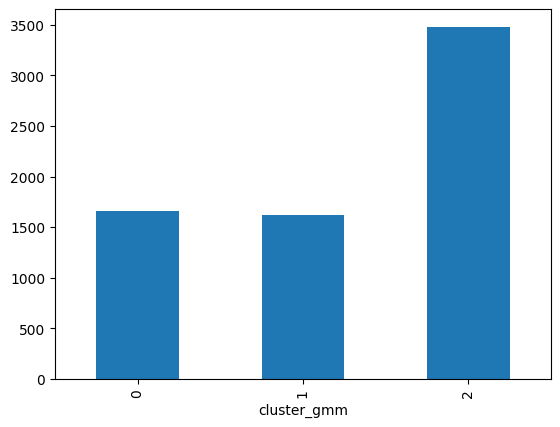

In [68]:
# Plot cluster counts for GMM
srch_destination_groups_std.groupby('cluster_gmm')['srch_destination_id'].agg('count').plot(kind='bar')

## Висновки:
Аналізуючи отримані графіки, можемо зробити наступні висновки:
##### Групування за hotel_market:
1) K-means: згідно з графіками методів Elbow та Silhouette Coefficient оптимальне К приймає наступні значення:
- Elbow: 2
- Silhouette Coefficient: 3
   
Фінальне рішення: К = 3  
Фінальне значення K = 3 було обрано на основі методу Silhouette Coefficient, оскільки він надає більш інформативну оцінку якості та роздільності кластерів.

2) GMM (Gaussian Mixture Model): GMM є імовірнісною моделлю, що оптимізує логарифм правдоподібності. Оскільки методи Elbow і Silhouette Coefficient оцінюють переважно геометричну структуру та роздільність кластерів, було прийнято рішення використовувати BIC (Bayesian Information Criterion) як додатковий критерій, щоб переконатися, що обрана кількість кластерів не призводить до надмірного спрощення структури даних. BIC використовується для вибору кількості кластерів, при якій модель досить добре описує дані і не є надмірно складною.

Оптимальні значення K за трьома методами:
- Elbow: 4
- Silhouette Coefficient: 3
- BIC: 6

Фінальне рішення: К = 3  
Хоча BIC вказує на більше значення K, було обрано K = 3 як компроміс між результатами критеріїв BIC (складністю моделі) та Silhouette Coefficient (якістю кластеризації), з пріоритетом на геометричну якість розбиття даних (Silhouette Coefficient).

##### Групування за srch_destination_id:
1) K-means:
- Elbow: 2
- Silhouette Coefficient: 3

Фінальне рішення: К = 3

2) GMM:
- Elbow: 3
- Silhouette Coefficient: 3
- BIC: 7

Фінальне рішення: К = 3

Отже, для обох групувань (hotel_market та srch_destination_id) K-Means і GMM призводять до однакового оптимального числа кластерів (K = 3).